In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import plot_tree, DecisionTreeClassifier

import matplotlib.pyplot as plt

#                                                   Theory
```js
        Read "Random Forest.pdf" in the Theory folder.
```

#                                           Difference between Bagging and Random Forest.
```js
        Their main difference is how the 'max_features' parameter works which is : 
                - The specific max_features number of columns (e.g. 'col1, col2') that will be used in Bagging is determined(constant) for each model before they start to make their own decision tree by splitting.

                - But in Random Forest the max_features number of columns that will be used is determined at each NODE LEVEL.
                
        If max_features = 2, then bagging’s e.g. 2nd model will use e.g. 'col1 and col2' the entire time but random forest’s 2nd model’s 1st node may use 'col1 and col3', 2nd node 'col5 and col9', so on which we visualized below.

        Medium : "By using a subset of the features at each node, random forest introduces diversity in the decision trees, which further reduces the variance of the model. Moreover, the feature selection process prevents the trees from being highly correlated, which is a problem in bagging. Therefore, the random forest can improve the accuracy of a model by reducing overfitting and increasing the diversity of the trees." Read their page -> https://medium.com/@divine_inner_voice/bagging-vs-random-forest-understanding-the-difference-f5272d33d02a.
                
                How random forest increases the diversity? Think tree as a building and node as each floor of the building. Now each floor of the random forest building has people from different countries but each floor of bagging has same country’s people.
```

#                                           Dataset creation.

In [60]:
X, y = make_classification(n_samples = 60, n_features = 10, n_informative = 5, random_state = 42) # 100 rows, 10 columns.
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print(f"{X[:5]}\n\n{y[:5]}")

[[ 2.49292161 -0.07530365 -0.12291131 -1.1012519   0.87102505 -0.05771411
  -2.3304683  -1.87140536  0.93081009  0.91967135]
 [ 1.92410524  1.44433879 -1.7308731   0.88606356 -1.2246735   3.71092808
   0.92664448  1.2579109   1.80296589 -0.99112793]
 [-1.92985947 -1.13914173  0.79773631  0.26774267  0.33490375  0.14608397
   2.38720627 -1.04243671 -1.25282312  2.52256877]
 [-0.61478857 -0.65437335 -1.06126263 -0.77322497 -1.55410997  2.54209151
   1.52157545  1.11338297  2.49914624  0.01779115]
 [ 0.73930103  1.39573194 -0.66840197 -1.30964929  0.44015309  2.36546547
   0.92661459 -1.97258885  3.54900753  4.26982464]]

[1 0 1 0 0]


#                                       How max_features works in Bagging.

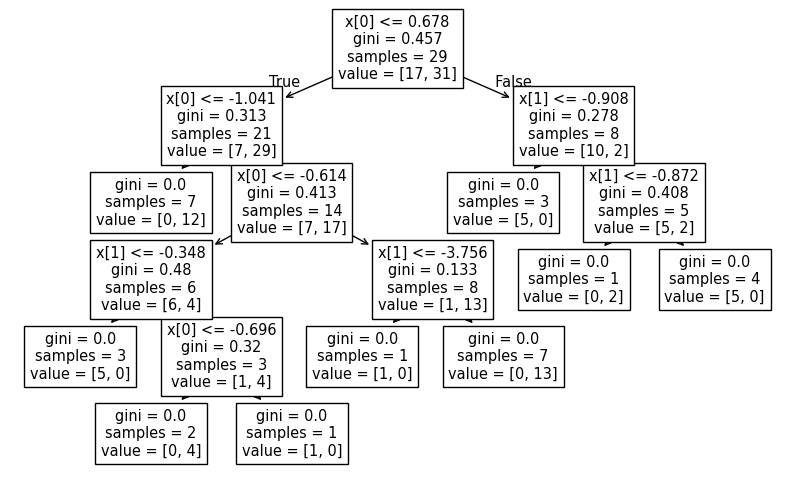

In [ ]:
bagging = BaggingClassifier(estimator = DecisionTreeClassifier(),
                            n_estimators = 5,
                            max_features = 2,
                            random_state = 42
                            
)
bagging.fit(X = x_train, y = y_train)

plt.figure(figsize = (10, 6))
plot_tree(decision_tree = bagging.estimators_[1])
plt.show()

explanation = """
-> The 'decision_tree' parameter of plot_tree must be an instance of 'DecisionTreeClassifier' or 'DecisionTreeRegressor'.

-> bagging.estimators_[1] = The second DecisionTreeClassifier used in this BaggingClassifier out of 5.

-> Since max_features = 2, bagging decided to give the 2nd model only the first two columns, x[0] and x[1]. That means now
   2nd model will build its entire decision tree based on that two columns. So at each Node Level, the data will be split
   either on x[0] column or x[1] column.

-> The max_features number of columns that'll be used to build the entire decision tree at each node for each model is
   decided before the tree is born i.e. before any splitting.
"""

#                                       How max_features works in Random Forest.

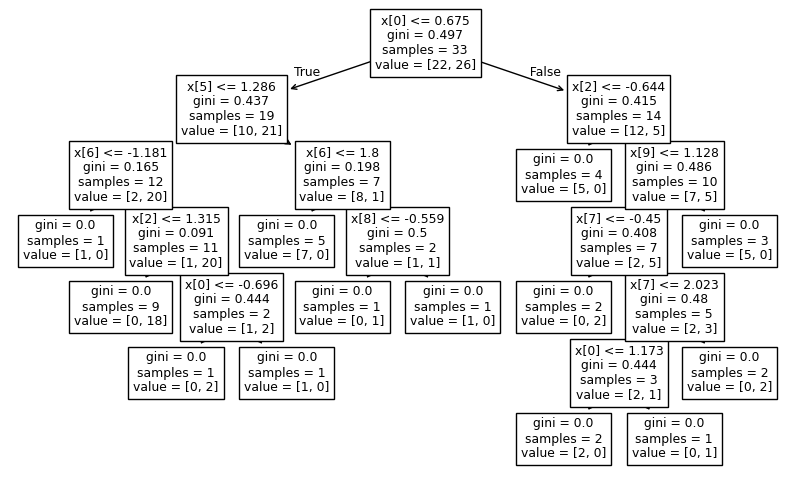

In [ ]:
rf = RandomForestClassifier(n_estimators = 5,
                            max_features = 2,
                            random_state = 42
                            
)
rf.fit(X = x_train, y = y_train)

plt.figure(figsize = (10, 6))
plot_tree(decision_tree = rf.estimators_[3])
plt.show()

explanation = """
-> The 'decision_tree' parameter of plot_tree must be an instance of 'DecisionTreeClassifier' or 'DecisionTreeRegressor'.

-> rf.estimators_[3] = The 4th DecisionTreeClassifier used in this andomForestClassifier out of 5.

-> Since max_features = 2, INITIALLY rf decided to give the 4th model the first two columns, x[0] and x[1] from where
   the first split will happen and x[0] column is chosen. Then at second left node rf decided that from that node the split
   will happen maybe based on x[5] and x[2] columns and the split happened on x[5] column. As you can see that at each NODE
   LEVEL, RF DECIDES/SAMPLES max_features NUMBER COLUMNS.

-> The max_features number of columns that'll be used to build the entire decision tree at each node for each model is
   decided at EACH NODE.
"""